In [411]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

from helpers import *
from implementations import *
from preprocessing import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [353]:
data_path = "/Users/AliSawyer/Documents/EPFL/M1/CS-433_Machine_learning/course-repo/ML_course/projects/project1/data/dataset"
names = open(f"{data_path}/x_train.csv").readline().strip().split(",")[1:]
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path)

In [226]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)

print(train_ids.shape)
print(test_ids.shape)

train_ids

(328135, 321)
(109379, 321)
(328135,)
(328135,)
(109379,)


array([     0,      1,      2, ..., 328132, 328133, 328134],
      shape=(328135,))

In [435]:
# add bias term (column of 1s) to the training data
# ones = np.ones(n)
# tx = np.column_stack((ones, x_train))

# preprocess data
tx_train, tx_test, features = preprocess(x_train, x_test, names)

# n is number of samples / data points
n = tx_train.shape[0]
# d is number of features
d = tx_train.shape[1]

tx_train

array([[ 1.        , -0.00987575,  0.59566875, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -0.00987575, -1.67878539, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -0.00987575,  0.59566875, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 1.        , -0.00987575, -1.67878539, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -0.00987575, -1.67878539, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.        , -0.00987575,  0.59566875, ...,  0.        ,
         0.        ,  0.        ]], shape=(328135, 256))

In [436]:
def random_undersample(x, y, und_ratio, seed=1):
    """ Randomly undersample the data to even out class imbalance:
        Randomly select only m samples from the MAJORITY class, where m equals the
        total number of samples in the dataset from the MINORITY class
    """
    np.random.seed(seed)
    labels, counts = np.unique(y, return_counts=True)
    m = counts.min()  # count of data points in minority class
    min_label = labels[counts.argmin()]  # minority class label
    maj_indices = np.where(y != min_label)[0]  # indices for data points in majority class
    min_indices = np.where(y == min_label)[0]  # indices for data points in minority class
    x_maj_only = x[maj_indices]  # dataset filtered for majority class only
    y_maj_only = y[maj_indices]  # dataset filtered for majority class only
    x_min_only = x[min_indices]  # dataset filtered for minority class only
    y_min_only = y[min_indices]  # dataset filtered for minority class only
    # create ndarray of randomized indices for undersampling
    # use argument for ratio of majority class labels to 1 minority class label
    und_rand_idx = np.random.permutation(m * und_ratio)
    # undersample majority class data points using randomly generated indices
    x_und = x_maj_only[und_rand_idx]
    y_und = y_maj_only[und_rand_idx]
    # print(x_und.shape)
    # print(y_und.shape)

    # randomly generate indices for final reshuffle
    recombine_rand_idx = np.random.permutation(und_rand_idx.shape[0] + m)
    # recombine with data points from the minority class
    x_recombine = np.concatenate([x_und, x_min_only])
    y_recombine = np.concatenate([y_und, y_min_only])
    
    return x_recombine[recombine_rand_idx], y_recombine[recombine_rand_idx]

In [428]:
def split_data(x, y, ratio, und_ratio=3, seed=1):
    """
    Split data into training and test sets based on provided ratio.
    """
    # set randomization seed for reproducibility
    np.random.seed(seed)
    n = x.shape[0]
    rand_idx = np.random.permutation(n)  # create ndarray of randomized indices
    training_size = int(np.floor(ratio * n))
    rand_idx_tr = rand_idx[:training_size]  # get randomized indices for the training set
    rand_idx_te = rand_idx[training_size:]  # get randomized indices for the test set

    x_tr = x[rand_idx_tr]  # use the training set of randomized indices to sample from x
    x_te = x[rand_idx_te]  # use the test set of randomized indices to sample from x
    y_tr = y[rand_idx_tr]  # use the training set of randomized indices to sample from y
    y_te = y[rand_idx_te]  # use the test set of randomized indices to sample from y

    # RANDOM UNDERSAMPLING to even out class imbalance
    x_tr, y_tr = random_undersample(x_tr, y_tr, und_ratio)

    return x_tr, x_te, y_tr, y_te


# use unusually high ratio since we will be randomly undersampling the training data to address class imbalance
ratio = 0.95
x_tr, x_te, y_tr, y_te = split_data(tx_train, y_train, ratio)
print(f"Split dataset shapes:\tx_train: {x_tr.shape}\ttx_test:{x_te.shape}\ty_train: {y_tr.shape}\ty_test: {y_te.shape}")

Split dataset shapes:	x_train: (110380, 256)	tx_test:(16407, 256)	y_train: (110380,)	y_test: (16407,)


[27595 27595]


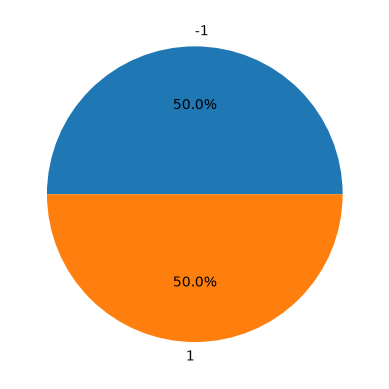

In [306]:
# Visualize breakdown of labels in y_tr
vals, counts = np.unique(y_tr, return_counts=True)
print(counts)
plt.pie(counts, labels=vals, autopct='%1.1f%%')
plt.show()

# class imbalance is approx 1:10 negative to positive
# https://machinelearningmastery.com/what-is-imbalanced-classification/

In [424]:
# Plotting and scoring functions
# Attribution: Code help from Claude AI chat

def line_chart_train_test(x, y1, y2):
    plt.semilogx(x, y1, color="b", marker=".", label="Train error")
    plt.semilogx(x, y2, color="c", marker=".", label="Test error")
    plt.xlabel("lambda")
    plt.ylabel("error")
    leg = plt.legend()
    plt.show()

def line_chart(x, x_label, y1, y1_label, y2, y2_label):
    plt.plot(x, y1, color="b", marker=".", label=y1_label)
    plt.plot(x, y2, color="c", marker=".", label=y2_label)
    plt.xlabel(x_label)
    plt.ylabel("Metrics")
    leg = plt.legend()
    plt.show()

def ordered_bar_chart(labels, values):
    labels = np.array(labels)
    values = np.array(values)
    order = np.argsort(values)   # ascending
    colors = plt.cm.tab10(np.arange(len(values)))
    plt.bar(labels[order], values[order], color=colors)
    plt.title("F1 Score Comparison for Different Learning Algorithms")
    plt.xticks(rotation=45, ha="right")
    plt.show()


def compute_f1(y_pred, y_test):
    """ Calculate F1 score: 2TP / (2TP + FP + FN) """
    tp = np.sum((y_pred == 1) & (y_test == 1))
    fp = np.sum((y_pred == 1) & (y_test == -1))
    fn = np.sum((y_pred == -1) & (y_test == 1))
    
    f1 = 2 * tp / (2 * tp + fp + fn)
    return f1.item()


def compute_accuracy(y_pred, y_test):
    """ Calculate accuracy: correct predictions over total predictions
        (TP + TN) / (TP + TN + FP + TN) """
    correct = np.sum(y_pred == y_test)
    total = y_pred.shape[0]
    
    return correct / total

In [231]:
def linear_classifier(x, w):
    """ Super simple linear classifier:
        Returns predictiction sign() (+/-1) of dot product of x and w
    """
    predictions = x @ w
    return np.sign(predictions)


test_f1_scores = []

# Linear regression
# Regular full-batch gradient descent first

initial_w = np.zeros(d)
max_iters = 1000
gamma = 0.1

# run training algorithm on training data to get optimal w
w_msegd, loss_msegd_tr = mean_squared_error_gd(y_tr, x_tr, initial_w, max_iters, gamma)

# get test loss
loss_msegd_te = calculate_mse(y_te, x_te, w_msegd)
print(f"Test loss: {loss_msegd_te}")

# using weights from gradient descent, run simple linear model on test set to get predictions
# get F1 score for comparison with other models
pred_msegd = linear_classifier(x_te, w_msegd)
f1_msegd = compute_f1(pred_msegd, y_te)
test_f1_scores.append(f1_msegd)
print(test_f1_scores)

Test loss: 0.13158404142707122
[0.08380258363696588]


In [232]:
# stochastic GD
initial_w = np.zeros(d)
max_iters = 5000
gamma = 0.0001

# run training algorithm (SGD) on training data to get optimal w
w_msesgd, loss_msesgd_tr = mean_squared_error_sgd(y_tr, x_tr, initial_w, max_iters, gamma)

# using weights from SGD, run simple linear model on test set to get predictions
# get F1 score for comparison with other models
pred_msesgd = linear_classifier(x_te, w_msesgd)
f1_msesgd = compute_f1(pred_msesgd, y_te)
test_f1_scores.append(f1_msesgd)
print(test_f1_scores)

[0.08380258363696588, 0.09869468322190385]


In [233]:
# Least squares

# run training algorithm on training data to get optimal w
w_ls, loss_ls_te = least_squares(y_tr, x_tr)

loss_ls_te = calculate_mse(y_te, x_te, w_ls)
print(loss_ls_te)

# using weights from least squares, run simple linear model on test set to get predictions
# get F1 score for comparison with other models
pred_ls = linear_classifier(x_te, w_ls)
f1_ls = compute_f1(pred_ls, y_te)
test_f1_scores.append(f1_ls)

0.1315978849523263


In [234]:
def find_best_lambda(f, f_args_tr, f_args_te):
    """ Compare over a range of lambda values to find one that results in lowest test error. 
        Args:
            f: Learning algorithm (function name) to run
            f_args_tr: Dict for positional args with which to run f for training
            f_args_te: Dict for positional args with which to run f for testing
        Returns: Best lambda value (based on test error)
    """
    # include 0 in the lambda values to try
    lambdas = np.concatenate(([0], np.logspace(-10, 0, 15)))
    # lambda_ = 0.01
    
    tr_losses = np.zeros(len(lambdas))
    te_losses = np.zeros(len(lambdas))
    for i, lambda_ in enumerate(lambdas):
        if "max_iters" in f_args_tr:  # we are doing GD, need initial_w
            initial_w_tr = np.zeros(d)
            initial_w_te = np.zeros(d)
            f_args_tr["initial_w"] = initial_w_tr
            f_args_te["initial_w"] = initial_w_te
        w_tr, loss_tr = f(**f_args_tr, lambda_=lambda_)
        w_te, loss_te = f(**f_args_te, lambda_=lambda_)
        tr_losses[i] = loss_tr
        te_losses[i] = loss_te
        print(f"Lambda: {lambda_}\tTraining loss: {loss_tr}\tTest loss: {loss_te}")
    
    min_idx_loss_tr = np.argmin(tr_losses)
    min_idx_loss_te = np.argmin(te_losses)
    best_lambda_tr = lambdas[min_idx_loss_tr]
    best_lambda_te = lambdas[min_idx_loss_te]
    print(f"Best lambda values:\tTrain: {best_lambda_tr} at idx {min_idx_loss_tr}\tTest: {best_lambda_te} at idx {min_idx_loss_te}")
    line_chart_train_test(lambdas, tr_losses, te_losses)

    return best_lambda_te

Lambda: 0.0	Training loss: 0.1341880136980107	Test loss: 0.1310005692300156
Lambda: 1e-10	Training loss: 0.13418801369801073	Test loss: 0.1310005692300156
Lambda: 5.179474679231202e-10	Training loss: 0.13418801369801128	Test loss: 0.13100056923001574
Lambda: 2.6826957952797275e-09	Training loss: 0.1341880136980266	Test loss: 0.13100056923001982
Lambda: 1.389495494373136e-08	Training loss: 0.1341880136984364	Test loss: 0.13100056923012887
Lambda: 7.196856730011529e-08	Training loss: 0.13418801370922948	Test loss: 0.13100056923303563
Lambda: 3.727593720314938e-07	Training loss: 0.13418801397316302	Test loss: 0.13100056930838885
Lambda: 1.9306977288832498e-06	Training loss: 0.13418801862172425	Test loss: 0.13100057101811927
Lambda: 1e-05	Training loss: 0.13418805131577696	Test loss: 0.13100059444803835
Lambda: 5.1794746792312125e-05	Training loss: 0.13418819991489211	Test loss: 0.1310007472673573
Lambda: 0.0002682695795279727	Training loss: 0.13418979901041955	Test loss: 0.131002503599014

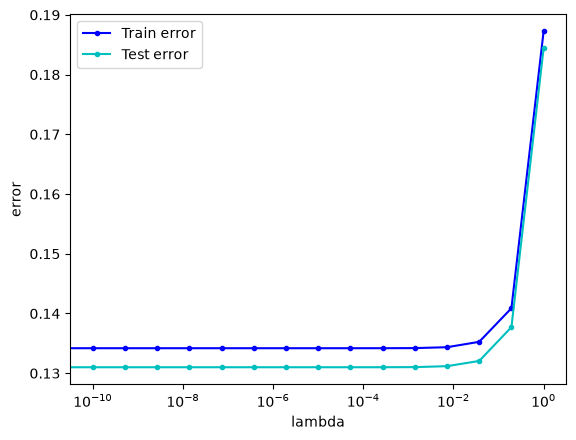

Test loss comparison:	Ridge regression: 0.1315978849523263	 vs Least squares: 0.1315978849523263


In [235]:
# Ridge regression
args_tr = { "y": y_tr, "tx": x_tr }
args_te = { "y": y_te, "tx": x_te }
best_lambda_te = find_best_lambda(ridge_regression, args_tr, args_te)

# run training algorithm on training data with best lambda to get optimal w
# with lambda_ = 0, this is exactly the same as least squares
w_rr, loss_rr_tr = ridge_regression(y_tr, x_tr, best_lambda_te)

# get test loss for ridge regression (MSE)
loss_rr_te = calculate_mse(y_te, x_te, w_rr)
# compare with least squares
loss_ls_te = calculate_mse(y_te, x_te, w_ls)
print(f"Test loss comparison:\tRidge regression: {loss_rr_te}\t vs Least squares: {loss_ls_te}")

# test_losses.append(loss_rr_te.item())
# print(test_losses)

(328135, 256)
Trying ratio: 1
Label counts before random undersampling: [199548  19209]
Counts after random undersampling: [19209 19209]
Logistic regression training loss: 0.4618439999990258
Logistic regression test loss: 0.48111528042337276
F1 score: 0.3779520007672205	Accuracy: 0.9151560957175771
Label counts before random undersampling: [199426  19331]
Counts after random undersampling: [19331 19331]
Logistic regression training loss: 0.46372735545028226
Logistic regression test loss: 0.4791962185001928
F1 score: 0.3737276279608278	Accuracy: 0.9151560957175771
Label counts before random undersampling: [199347  19410]
Counts after random undersampling: [19410 19410]
Logistic regression training loss: 0.46319321201550695
Logistic regression test loss: 0.4812220569003203
F1 score: 0.37144377782078575	Accuracy: 0.9151560957175771
Trying ratio: 3
Label counts before random undersampling: [199548  19209]
Counts after random undersampling: [57627 19209]
Logistic regression training loss: 0

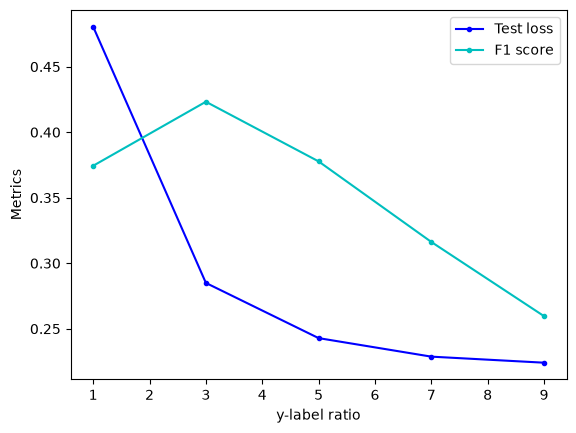

In [425]:
# Logistic regression
max_iters = 1000
gamma = 0.1
# number of folds to use for K-fold cross validation
k_fold = 3
# ratios for number of majority-class samples : 1 minority-class sample
ratios = np.arange(1, 10, 2)
seed = 1
np.random.seed(seed)

# convert y labels from -1/+1 to 0/1 to work with logistic loss function
y_conv = (y_train + 1) / 2

# do K-fold cross-validation on logistic regression
n = tx_train.shape[0]
print(tx_train.shape)
fold_size = int(n / k_fold)
rand_indices = np.random.permutation(n)

# cross-validation over ratios for random undersampling
te_losses = []
f1s = []
und_seeds = np.random.permutation(k_fold)  # seeds for random undersampling
for ratio in ratios:
    print(f"Trying ratio: {ratio}")
    ratio_te_loss = 0
    ratio_f1 = 0
    for k in range(k_fold):
        # test set indices: current fold
        fold_te_indices = rand_indices[k * fold_size : (k+1) * fold_size]
        # training set indices: all data points not in test set are for training
        fold_tr_indices = rand_indices[~np.isin(rand_indices, fold_te_indices)]
    
        x_tr = tx_train[fold_tr_indices]
        y_tr = y_conv[fold_tr_indices]
        x_te = tx_train[fold_te_indices]
        y_te = y_conv[fold_te_indices]
    
        # randomly undersample data to even out class imbalance
        _, counts_before = np.unique(y_tr, return_counts=True)
        print(f"Label counts before random undersampling: {counts_before}")
        x_tr_und, y_tr_und = random_undersample(x_tr, y_tr, ratio, und_seeds[k])
        _, counts_after = np.unique(y_tr_und, return_counts=True)
        print(f"Counts after random undersampling: {counts_after}")
        
        # run training algorithm on training data to get optimal w
        initial_w = np.zeros(x_tr_und.shape[1])
        w_log, loss_log_tr = logistic_regression(y_tr_und, x_tr_und, initial_w, max_iters, gamma)
        # also calculate negative LL loss on TEST data to compare
        loss_log_te = calculate_neg_ll_loss(y_te, x_te, w_log)
        ratio_te_loss += loss_log_te
        # only sign(x @ w) matters to predict class, so we can also use linear_classifier() here
        pred_log = linear_classifier(x_te, w_log)
    
        # convert y labels back to -1/+1
        y_te = 2 * y_te - 1
        # get F1 score for comparison with other models
        f1_log = compute_f1(pred_log, y_te)
        ratio_f1 += f1_log
        print(f"Logistic regression training loss: {loss_log_tr}\tTest loss: {loss_log_te}\tF1 score: {f1_log}")
    te_losses.append(ratio_te_loss / k_fold)  # average loss over K-fold for given ratio
    f1s.append(ratio_f1 / k_fold)  # average F1 score over K-fold for given ratio

# plot comparison of different ratios
line_chart(ratios, "y-label ratio", te_losses, "Test loss", f1s, "F1 score")

(328135, 256)
Trying ratio: 1
Label counts before random undersampling: [224440  21662]
Counts after random undersampling: [21662 21662]
Label counts before random undersampling: [224382  21720]
Counts after random undersampling: [21720 21720]
Label counts before random undersampling: [224444  21658]
Counts after random undersampling: [21658 21658]
Label counts before random undersampling: [224217  21885]
Counts after random undersampling: [21885 21885]
Averages for ratio 1:	Logistic regression test loss: 0.48000657313008555	F1 score: 0.37441193066995937
Trying ratio: 2
Label counts before random undersampling: [224440  21662]
Counts after random undersampling: [43324 21662]
Label counts before random undersampling: [224382  21720]
Counts after random undersampling: [43440 21720]
Label counts before random undersampling: [224444  21658]
Counts after random undersampling: [43316 21658]
Label counts before random undersampling: [224217  21885]
Counts after random undersampling: [43770 21

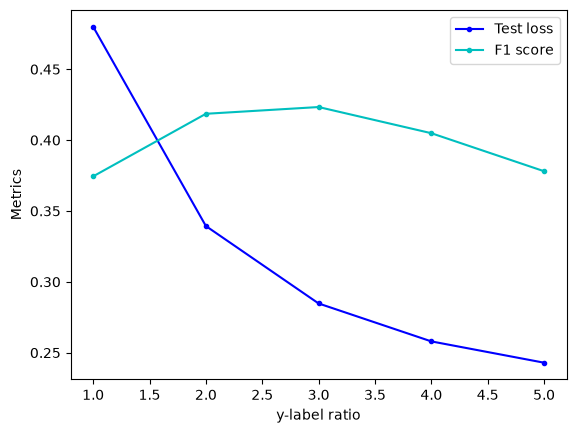

In [427]:
# Logistic regression
max_iters = 1000
gamma = 0.1
# number of folds to use for K-fold cross validation
k_fold = 4
# ratios for number of majority-class samples : 1 minority-class sample
ratios = np.arange(1, 6)
seed = 1
np.random.seed(seed)

# convert y labels from -1/+1 to 0/1 to work with logistic loss function
y_conv = (y_train + 1) / 2

# do K-fold cross-validation on logistic regression
n = tx_train.shape[0]
print(tx_train.shape)
fold_size = int(n / k_fold)
rand_indices = np.random.permutation(n)

# cross-validation over ratios for random undersampling
te_losses = []
f1s = []
und_seeds = np.random.permutation(k_fold)  # seeds for random undersampling
for ratio in ratios:
    print(f"Trying ratio: {ratio}")
    ratio_te_loss = 0
    ratio_f1 = 0
    for k in range(k_fold):
        # test set indices: current fold
        fold_te_indices = rand_indices[k * fold_size : (k+1) * fold_size]
        # training set indices: all data points not in test set are for training
        fold_tr_indices = rand_indices[~np.isin(rand_indices, fold_te_indices)]
    
        x_tr = tx_train[fold_tr_indices]
        y_tr = y_conv[fold_tr_indices]
        x_te = tx_train[fold_te_indices]
        y_te = y_conv[fold_te_indices]
    
        # randomly undersample data to even out class imbalance
        _, counts_before = np.unique(y_tr, return_counts=True)
        print(f"Label counts before random undersampling: {counts_before}")
        x_tr_und, y_tr_und = random_undersample(x_tr, y_tr, ratio, und_seeds[k])
        _, counts_after = np.unique(y_tr_und, return_counts=True)
        print(f"Counts after random undersampling: {counts_after}")
        
        # run training algorithm on training data to get optimal w
        initial_w = np.zeros(x_tr_und.shape[1])
        w_log, loss_log_tr = logistic_regression(y_tr_und, x_tr_und, initial_w, max_iters, gamma)
        # also calculate negative LL loss on TEST data to compare
        loss_log_te = calculate_neg_ll_loss(y_te, x_te, w_log)
        ratio_te_loss += loss_log_te
        # only sign(x @ w) matters to predict class, so we can also use linear_classifier() here
        pred_log = linear_classifier(x_te, w_log)
    
        # convert y labels back to -1/+1
        y_te = 2 * y_te - 1
        # get F1 score for comparison with other models
        f1_log = compute_f1(pred_log, y_te)
        ratio_f1 += f1_log
    avg_te_loss = ratio_te_loss / k_fold  # average loss over K-fold for given ratio
    te_losses.append(avg_te_loss)
    avg_f1 = ratio_f1 / k_fold  # average F1 score over K-fold for given ratio
    f1s.append(avg_f1)
    print(f"Averages for ratio {ratio}:\tLogistic regression test loss: {avg_te_loss}\tF1 score: {avg_f1}")

# plot comparison of different ratios
line_chart(ratios, "y-label ratio", te_losses, "Test loss", f1s, "F1 score")

In [438]:
# FINAL MODEL TRAINING
# train last model using best ratio with no K-folds
max_iters = 1000
gamma = 0.1
best_und_ratio = 3  # best ratio based on F1-score, determined through cross-validation

y_conv = (y_train + 1) / 2
x_tr, y_tr = random_undersample(tx_train, y_conv, best_und_ratio)
_, counts_after = np.unique(y_tr, return_counts=True)
print(f"Label counts after random undersampling: {counts_after}")
initial_w = np.zeros(x_tr.shape[1])
w_log_final, loss_log_tr_final = logistic_regression(y_tr, x_tr, initial_w, max_iters, gamma)
print(f"Last logistic regression training loss: {loss_log_tr_final}")

Label counts after random undersampling: [86925 28975]
Last logistic regression training loss: 0.38989208790913704


In [430]:
# Regularized logistic regression - NOT USED for final model

# train last model using best ratio with no K-folds
max_iters = 500
gamma = 0.1

ratio = 0.8  # test/train split ratio
best_und_ratio = 3  # ratio for majority:minority class labels based on F1-score, as selected through cross-validation
y_conv = (y_train + 1) / 2
x_tr, x_te, y_tr, y_te = split_data(tx_train, y_conv, ratio, best_und_ratio)

args_tr = { "y": y_tr, "tx": x_tr, "max_iters": max_iters, "gamma": gamma }
args_te = { "y": y_te, "tx": x_te, "max_iters": max_iters, "gamma": gamma }
best_lambda_te = find_best_lambda(reg_logistic_regression, args_tr, args_te)

# with lambda_ = 0, exactly the same as regular (unpenalized) logistic regression

Iteration 0:	Loss: 0.644235961874936
Iteration 100:	Loss: 0.39873395559187014
Iteration 200:	Loss: 0.394318663167267
Iteration 300:	Loss: 0.3927405967904602
Iteration 400:	Loss: 0.3918606030034207
Iteration 0:	Loss: 0.6274695068130163
Iteration 100:	Loss: 0.2344765399798944
Iteration 200:	Loss: 0.22799948545593182
Iteration 300:	Loss: 0.22604330952421323
Iteration 400:	Loss: 0.22503777371060282
Lambda: 0.0	Training loss: 0.39129791165011607	Test loss: 0.2243983476290688
Iteration 0:	Loss: 0.644235961874936
Iteration 100:	Loss: 0.39873395561375075
Iteration 200:	Loss: 0.39431866318596953
Iteration 300:	Loss: 0.392740596809238
Iteration 400:	Loss: 0.3918606030231401
Iteration 0:	Loss: 0.6274695068130163
Iteration 100:	Loss: 0.23447654002016213
Iteration 200:	Loss: 0.22799948549116475
Iteration 300:	Loss: 0.22604330955572988
Iteration 400:	Loss: 0.22503777374040632
Lambda: 1e-10	Training loss: 0.39129791167070577	Test loss: 0.22439834765843006
Iteration 0:	Loss: 0.644235961874936
Iteratio

KeyboardInterrupt: 

In [ ]:
# compare models
labels = ["Linear regression with GD", "Linear regression with SGD", "Least squares", "Logistic regression"]
ordered_bar_chart(labels, test_f1_scores)

In [439]:
# check relative importance/influence of features on the prediction
# w_log is best weights found so far

most_impact_indices = np.argsort(np.abs(w_log_final))[::-1][:10]
most_impact_features = np.array(features)[most_impact_indices]
most_impact_features

array(['bias', '_AGEG5YR', '_RACE=1', 'SEX', 'GENHLTH', 'RENTHOM1=1',
       '_PRACE1=1', 'MARITAL=5', 'EMPLOY1=1', 'BPHIGH4'], dtype='<U16')

In [325]:
# prediction confidence
p = 1 / (1 + np.exp(-(x_te @ w_log_final)))
confidence = np.maximum(p, 1 - p)
min_confidence = np.argsort(confidence)[:10]  # 5 lowest confidence
print(x_te[min_confidence])
features[:5]

[[ 1.         -0.00987575 -1.67878539 ...  0.          0.
   0.        ]
 [ 1.         -0.00987575 -1.67878539 ...  0.          0.
   0.        ]
 [ 1.         -0.00987575 -1.67878539 ...  0.          0.
   0.        ]
 ...
 [ 1.         -0.00987575  0.59566875 ...  0.          0.
   0.        ]
 [ 1.         -0.00987575 -1.67878539 ...  0.          0.
   0.        ]
 [ 1.         -0.00987575  0.59566875 ...  0.          0.
   0.        ]]


['bias', 'PVTRESD1', 'CELLFON3', 'NUMADULT', 'NUMMEN']

In [329]:
min_idx = np.where(y_te == 1)[0]  # indices in test dataset with minority label (+1)
hit = min_idx[pred_log[min_idx] == 1]  # model predicted correctly
miss = min_idx[pred_log[min_idx] != 1]  # model predicted wrong

# feature means: feature diff for caught vs missed, for minority label
means_diff = x_te[hit].mean(axis=0) - x_te[miss].mean(axis=0)
# get biggest diffs
max_diffs = np.argsort(means_diff)[::-1][:5]  # descending
feature_array = np.array(features)
feature_array[max_diffs]

array(['_RFHLTH', 'GENHLTH', '_AGE65YR', '_AGEG5YR', 'PHYSHLTH'],
      dtype='<U16')

In [440]:
# create submission to submit on competition platform
# predict against real test set
pred_submit = linear_classifier(tx_test, w_log_final)
print(np.unique(pred_submit, return_counts=True))

create_csv_submission(test_ids, pred_submit, "team_CAM2.csv")

(array([-1.,  1.]), array([96305, 13074]))


In [421]:
np.savetxt("preprocessed_data.csv", tx_train, delimiter=",", header=",".join(features), fmt="%.4g")